<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex02_Perceptron%EA%B3%BC_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 학습목표
- 퍼셉트론의 구조를 이해한다
- XOR문제를 해결하는 MLP 구조를 이해한다

### 퍼셉트론
- 인공신경망의 기본 단위인 뉴런의 생물학적 동작을 모방한 수학모델
- 입력신호에 대한 변환과 역치 매커니즘을 구현

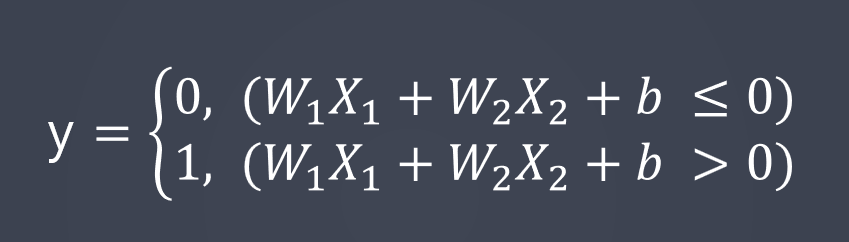

#### 활성화 함수 구현
- 초기에는 step functoin을 활용

In [ ]:
import numpy as np

In [ ]:
def step_activation(x) :
  '''x : 선형모델이 출력한 값'''
  if x > 0 :
    return 1 # 활성화
  else :
    return 0 # 비활성화


In [ ]:
def linear(x) :
  ''' x : 선형모델에 들어오는 입력 특성 '''
  w = 0.2
  b = -0.3
  return w * x + b # y값 반환

In [ ]:
def my_perceptron(x) :
  a = linear(x) # 선형모델 연산
  return step_activation(a) # 역치 매커니즘 적용(활성화함수)

In [ ]:
my_perceptron(10)

1

#### AND 연산 퍼셉트론 만들기

In [ ]:
def AND_linear(x1, x2) :
  '''
    x1 : 첫번째 입력 비트 (0 or 1)
    x2 : 두번째 입력 비트 (0 or 1)
  '''
  w1 = 1
  w2 = 1
  b = -1.5
  return w1 * x1 + w2 * x2 + b

In [ ]:
def AND_perceptron(x1, x2) :
  a = AND_linear(x1, x2) # 선형모델 연산
  return step_activation(a) # 역치 매커니즘 적용

In [ ]:
print(AND_perceptron(1,1))
print(AND_perceptron(0,1))
print(AND_perceptron(1,0))
print(AND_perceptron(0,0))

1
0
0
0


#### OR 퍼셉트론 만들어보기 (실습)
- OR_linear 함수 만들기
- OR_perceptron 함수 만들기
- 4가지 케이스 테스트

In [ ]:
def OR_linear(x1, x2) :
  '''
    x1 : 첫번째 입력 비트 (0 or 1)
    x2 : 두번째 입력 비트 (0 or 1)
  '''
  w1 = 1
  w2 = 1
  b = -0.5
  return w1 * x1 + w2 * x2 + b

In [ ]:
def OR_perceptron(x1, x2) :
  a = OR_linear(x1, x2) # 선형모델 연
  return step_activation(a) # 역치 매커니즘 적용

In [ ]:
print(OR_perceptron(1,1))
print(OR_perceptron(0,1))
print(OR_perceptron(1,0))
print(OR_perceptron(0,0))

1
1
1
0


### MLP (다층퍼셉트론)
- 여러개의 퍼셉트론을 층층이 쌓아 구성하는 모델구조
- 차원을 높여 복잡한 선을 구성할 수 있는 능력이 생김
- XOR 같은 문제를 해결

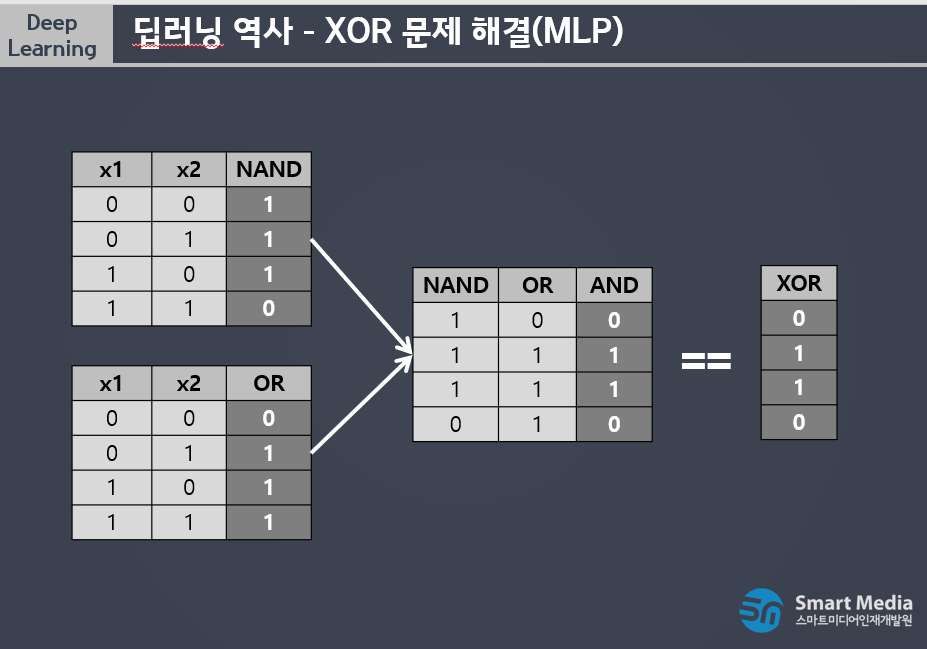

### NAND 퍼셉트론 만들기

In [ ]:
def NAND_linear(x1, x2) :
  '''
    x1 : 첫번째 입력 비트 (0 or 1)
    x2 : 두번째 입력 비트 (0 or 1)
  '''
  w1 = -1
  w2 = -1
  b = 1.2
  return w1 * x1 + w2 * x2 + b

In [ ]:
def NAND_perceptron(x1, x2) :
  a = NAND_linear(x1, x2) # 선형모델 연
  return step_activation(a) # 역치 매커니즘 적용

In [ ]:
print(NAND_perceptron(1,1))
print(NAND_perceptron(0,1))
print(NAND_perceptron(1,0))
print(NAND_perceptron(0,0))

0
1
1
1


### XOR MLP 만들기


In [ ]:
def XOR_MLP(x1, x2) :
  # 첫번째 층 연산
  a1 = NAND_perceptron(x1, x2)
  a2 = OR_perceptron(x1, x2)
  # 두번째 층 연산
  z = AND_perceptron(a1, a2)

  return z

In [ ]:
print(XOR_MLP(0,0))
print(XOR_MLP(1,1))
print(XOR_MLP(1,0))
print(XOR_MLP(0,1))

0
0
1
1


### Keras활용 XOR MLP 만들기

In [ ]:
# 데이터셋 구성하기
X = np.array([[0,0],
              [1,0],
              [0,1],
              [1,1]])
y = np.array([0,1,1,0])

In [ ]:
from tensorflow.keras.models import Sequential # 인공신경망을 구성하는 기본 틀
from tensorflow.keras.layers import Dense # 퍼셉트론의 묶음을 표현하는 도구
from tensorflow.keras.layers import InputLayer # 입력층을 표현하는 도구

In [ ]:
# 모델설계
xor_model = Sequential() # 인공신경망 틀 생성
## 입력층
xor_model.add(InputLayer(shape=(2,)))
## 중간층(은닉층)
xor_model.add(Dense(units=20, activation='sigmoid'))
xor_model.add(Dense(units=30, activation='sigmoid'))
xor_model.add(Dense(units=20, activation='sigmoid'))
## 출력층
xor_model.add(Dense(units=1, activation='sigmoid'))


In [ ]:
# 학습 및 평가방법 설정
xor_model.compile(loss="binary_crossentropy", # 손실함수 : 모델의 오차 계산
                  optimizer="adam", # 최적화 알고리즘 : loss를 기반으로 w,b의 수정을 최적화(방향계산)
                  metrics=['accuracy']) # 평가지표 : 분류용 평가지표 설정

In [ ]:
# 학습
xor_model.fit(X,y,
              epochs = 500)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6967
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5000 - loss: 0.6953
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5000 - loss: 0.6943
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5000 - loss: 0.6937
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5000 - loss: 0.6933
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5000 - loss: 0.6932
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5000 - loss: 0.6932
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5000 - loss: 0.6934
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5000 - loss: 0.6936
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5000 - loss: 0.6937
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5000 - loss: 0.6938
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss

In [ ]:
# 추론
xor_model.predict(np.array([[0,1]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([[0.95529795]], dtype=float32)

In [ ]:
xor_model.predict(np.array([[1,1]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


array([[0.05877326]], dtype=float32)